# DC Extrapolation for Time Domain 

When converting S-parameters to time domain the frequency points should be equally spaced and start from 0 Hz. Usually VNA doesn't measure down to DC and DC point should be added afterwards.

When a DC point measurement is added it might be the case that frequency point spacing between the DC and the first measured point is not equal to the spacing between the other measured points. Since time domain conversion relies on Fourier transform that assumes regularly spaced points, the measurements should also be resampled to be equally spaced.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

import skrf as rf
from skrf.media import Coaxial
from skrf.plotting import stylely

stylely()

In [2]:
freq = rf.Frequency(0.11, 110, 401, 'GHz')
coax1mm = Coaxial(freq, Dint=0.44e-3, Dout=1.0e-3, sigma=1e20, z0_port = 50)

X = coax1mm.line(10, unit='mm', z0=50, name='X')
Y = coax1mm.line(80, unit='mm', z0=75, name='Y')
dut = X**Y**X
dut.name = 'Original'

dut_dc = dut.extrapolate_to_dc(dc_sparam=[[0,1],[1,0]])
dut_dc.name = 'Extrapolated'

/home/alex/code/scikit-rf-docs/skrf/network.py:5255: RuntimeWarning: Frequency doesn't begin from 0. Step response will not be correct.
  x, y = self.step_response(**t_func_kwargs)


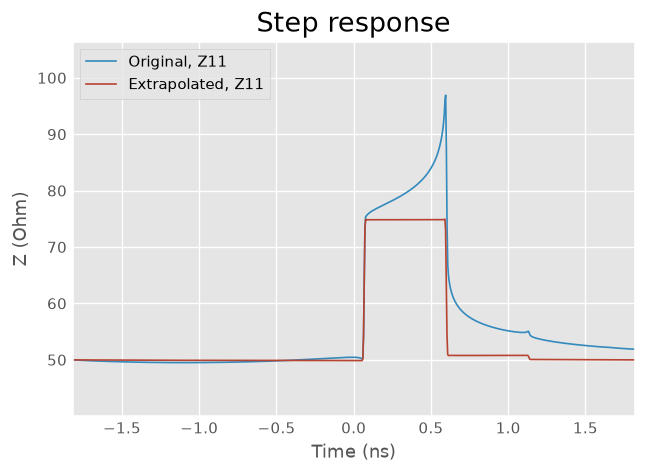

In [3]:
plt.figure()
plt.title('Step response')
dut.plot_z_time_step(0, 0)
dut_dc.plot_z_time_step(0, 0)

## Interpolation method comparison

In [4]:
# Frequency points for measurements to be interpolated
# Frequencies from 0 to 1 GHz are missing
freq = rf.Frequency(1, 110, 601, 'GHz')
# Frequency for ideal
freq2 = rf.Frequency(0, 110, 602, 'GHz')
coax1mm = Coaxial(freq, z0_port=50, Dint=0.44e-3, Dout=1.0e-3, sigma=1e20)
coax1mm2 = Coaxial(freq2, z0_port=50, Dint=0.44e-3, Dout=1.0e-3, sigma=1e20)

# Generate the DUT
X = coax1mm.line(10, 'mm', z0=50, name='X')
Y = coax1mm.line(80, 'mm', z0=75, name='Y')
dut = X**Y**X

# DUT with full frequencies for comparison
X2 = coax1mm2.line(10, 'mm', z0=50, name='X')
Y2 = coax1mm2.line(80, 'mm', z0=75, name='Y')
dut_ideal = X2**Y2**X2
dut_ideal.name = 'ideal'

# Extrapolate to DC with different methods
dut_dc_rational = dut.extrapolate_to_dc(kind='rational', dc_sparam=[[0,1],[1,0]])
dut_dc_rational.name = 'rational'
dut_dc_linear = dut.extrapolate_to_dc(kind='linear', dc_sparam=[[0,1],[1,0]])
dut_dc_linear.name = 'linear'
dut_dc_cubic = dut.extrapolate_to_dc(kind='cubic', dc_sparam=[[0,1],[1,0]])
dut_dc_cubic.name = 'cubic'

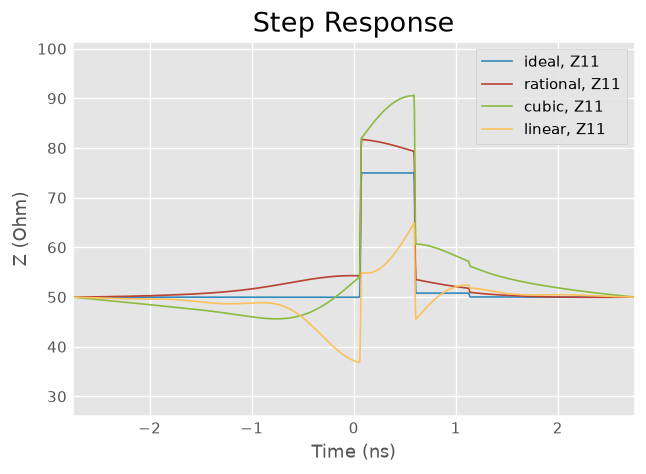

In [5]:
plt.figure()
plt.title('Step Response')
dut_ideal.plot_z_time_step(0, 0)
dut_dc_rational.plot_z_time_step(0, 0)
dut_dc_cubic.plot_z_time_step(0, 0)
dut_dc_linear.plot_z_time_step(0, 0)

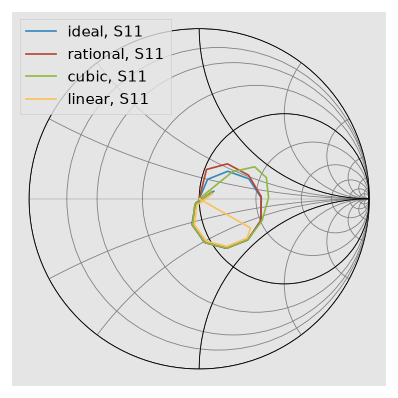

In [6]:
dut_ideal.s11['0-2ghz'].plot_s_smith()
dut_dc_rational.s11['0-2ghz'].plot_s_smith()
dut_dc_cubic.s11['0-2ghz'].plot_s_smith()
dut_dc_linear.s11['0-2ghz'].plot_s_smith()

## Interpolation basis

By default S-parameters are interpolated, but it's possible to interpolate also other parameters such as T, ABCD, Z or Y-parameters.

Usually S-parameters are the best choice, but in this case T-parameters give better results. Note that T-parameters are defined only for two-ports with non-zero S21. It probably isn't the best choice in most cases but for well matched transmissive two-ports it might be worth trying.

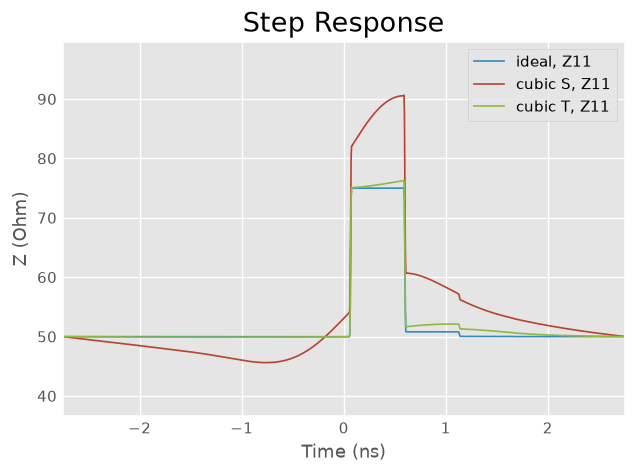

In [7]:
dut_dc_cubic_t = dut.extrapolate_to_dc(kind='cubic', dc_sparam=[[0,1],[1,0]], basis='t')
dut_dc_cubic_t.name = 'cubic T'
dut_dc_cubic.name = 'cubic S'

plt.figure()
plt.title('Step Response')
dut_ideal.plot_z_time_step(0, 0)
dut_dc_cubic.plot_z_time_step(0, 0)
dut_dc_cubic_t.plot_z_time_step(0, 0)

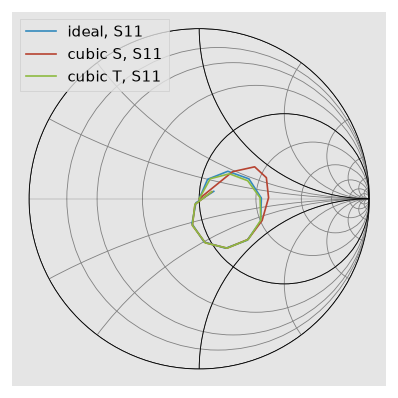

In [8]:
dut_ideal.s11['0-2ghz'].plot_s_smith()
dut_dc_cubic.s11['0-2ghz'].plot_s_smith()
dut_dc_cubic_t.s11['0-2ghz'].plot_s_smith()